# **Power law Transformer**

It estimates a transformation parameter from the training data rather than requiring you to manually choose a fixed function such as log1p or sqrt. The goal is to make the transformed feature more Gaussian-like (more bell-shaped) and, potentially, stabilize its variance.


In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [25]:
df = pd.read_csv("data/titanic.csv").drop(columns=["PassengerId", "Ticket", "Cabin"])

In [26]:
df.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,7.2500,S
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,71.2833,C
2,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,7.9250,S
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,53.1000,S
4,0,3,"Allen, Mr. William Henry",male,35.0,0,0,8.0500,S


In [44]:
df[df["Fare"]==0]

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked
179,0,3,"Leonard, Mr. Lionel",male,36.0,0,0,0.0,S
263,0,1,"Harrison, Mr. William",male,40.0,0,0,0.0,S
271,1,3,"Tornquist, Mr. William Henry",male,25.0,0,0,0.0,S
277,0,2,"Parkes, Mr. Francis ""Frank""",male,NaN,0,0,0.0,S
302,0,3,"Johnson, Mr. William Cahoone Jr",male,19.0,0,0,0.0,S
413,0,2,"Cunningham, Mr. Alfred Fleming",male,NaN,0,0,0.0,S
466,0,2,"Campbell, Mr. William",male,NaN,0,0,0.0,S
481,0,2,"Frost, Mr. Anthony Wood ""Archie""",male,NaN,0,0,0.0,S
597,0,3,"Johnson, Mr. Alfred",male,49.0,0,0,0.0,S
633,0,1,"Parr, Mr. William Henry Marsh",male,NaN,0,0,0.0,S


In [47]:
# making funciton for applying different function transformer on the dataset


from sklearn.preprocessing import PowerTransformer


def transformer(meth, col):
    transform = PowerTransformer(method=meth)
    Fare_transform = transform.fit_transform(df[[col]])
    fig, axe = plt.subplots(1, 2, figsize=(12, 4))
    sns.kdeplot(df["Fare"], ax=axe[0])
    axe[0].set_title("Before transformation")
    sns.kdeplot(Fare_transform, ax=axe[1])
    axe[1].set_title("After transformation")
    fig.show()
    
    

# **Box-Cox transformer**
Box-Cox is designed for features whose values are strictly greater than zero

C:\Users\HP\AppData\Local\Temp\ipykernel_172284\1710878580.py:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


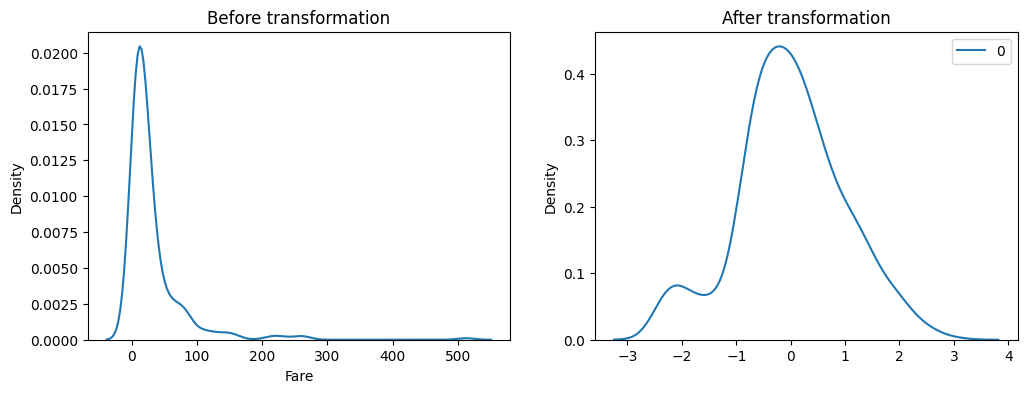

In [48]:
transformer("box-cox", "Age")

<br>

# **Yeo-Johnson**

Yeo-Johnson is an extension that can handle positive, zero, and negative values.

C:\Users\HP\AppData\Local\Temp\ipykernel_172284\1710878580.py:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


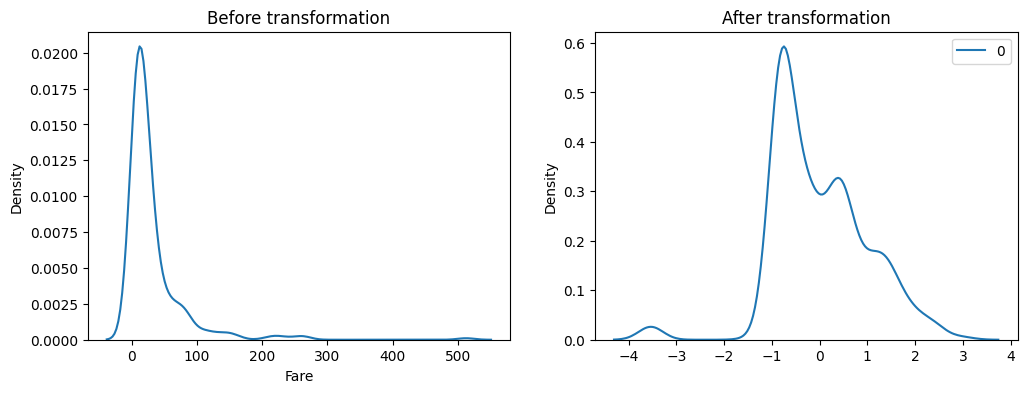

In [49]:
transformer("yeo-johnson", "Fare")

